# 05 — CatBoost per generator

**Group 119 — Henrik Remmen (541747)**  
**Kaggle team:** `[119] SINTEF Databreach`

This experiment trains one CatBoost classifier for each of the 14 generators. It uses the same engineered feature matrix and purged chronological folds as notebook 04.

> Saved unexecuted. Run the cells yourself. Model selection is based on mean and worst-fold micro ROC-AUC, not the public leaderboard alone.


## 1. Setup and identical feature pipeline

Set `FEATURE_SET` to the feature block selected in notebook 04. `full_engineered` is the current default.

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.sintef_pipeline import (
    HORIZON,
    RANDOM_SEED,
    build_project_data,
    make_submission,
    micro_auc,
    per_unit_auc,
    rows_for_cases,
)

try:
    from catboost import CatBoostClassifier
except ImportError as error:
    raise ImportError(
        "Install project dependencies with: pip install -r requirements.txt"
    ) from error

sns.set_theme(style="whitegrid", context="notebook")
N_JOBS = 4
FEATURE_SET = "full_engineered"

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


In [2]:
# DATA/FEATURE CELL — does not train a model
data = build_project_data(ROOT)
FEATURES = data.feature_sets[FEATURE_SET]

print("Feature set:", FEATURE_SET)
print("Number of features:", len(FEATURES))
print("Feature matrix:", data.X_all.shape)
print("Target cube:", data.target_cube.shape)
display(pd.DataFrame([
    {
        "validation_year": fold["year"],
        "train_cases": len(fold["train_cases"]),
        "validation_cases": len(fold["validation_cases"]),
    }
    for fold in data.folds
]))


Feature set: full_engineered
Number of features: 175
Feature matrix: (612696, 175)
Target cube: (2922, 14, 168)


,validation_year,train_cases,validation_cases
0,2020,1820,366
1,2021,2186,365
2,2022,2551,365


## 2. CatBoost definition and OOF evaluation

The initial configuration is intentionally small and controlled. Tune only after this result is recorded.

In [3]:
CATBOOST_PARAMS = {
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "iterations": 1800,
    "learning_rate": 0.035,
    "depth": 7,
    "l2_leaf_reg": 6.0,
    "random_strength": 0.5,
    "subsample": 0.85,
    "bootstrap_type": "Bernoulli",
    "random_seed": RANDOM_SEED,
    "thread_count": N_JOBS,
    "allow_writing_files": False,
    "verbose": False,
}

def make_catboost(iterations=None):
    params = dict(CATBOOST_PARAMS)
    if iterations is not None:
        params["iterations"] = int(iterations)
    return CatBoostClassifier(**params)

def evaluate_catboost_per_generator():
    oof = np.full(data.target_cube.shape, np.nan, dtype=np.float32)
    best_iterations = {unit: [] for unit in data.units}
    fold_rows = []
    unit_rows = []

    for fold in data.folds:
        started = time.perf_counter()
        train_case_ids = fold["train_cases"]
        val_case_ids = fold["validation_cases"]
        train_rows = rows_for_cases(train_case_ids)
        val_rows = rows_for_cases(val_case_ids)
        X_train = data.X_all.loc[train_rows, FEATURES]
        X_val = data.X_all.loc[val_rows, FEATURES]
        fold_prediction = np.empty(
            (len(val_case_ids), len(data.units), HORIZON),
            dtype=np.float32,
        )

        for unit_index, unit in enumerate(data.units):
            y_train = data.target_cube[train_case_ids, unit_index, :].reshape(-1)
            y_val = data.target_cube[val_case_ids, unit_index, :].reshape(-1)
            model = make_catboost()
            model.fit(
                X_train,
                y_train,
                eval_set=(X_val, y_val),
                early_stopping_rounds=120,
                verbose=False,
            )
            prediction = model.predict_proba(X_val)[:, 1]
            fold_prediction[:, unit_index, :] = prediction.reshape(
                len(val_case_ids), HORIZON
            )
            best_iterations[unit].append(model.get_best_iteration() + 1)

        oof[val_case_ids] = fold_prediction
        score = micro_auc(data.target_cube[val_case_ids], fold_prediction)
        elapsed = time.perf_counter() - started
        fold_rows.append({
            "validation_year": fold["year"],
            "micro_auc": score,
            "seconds": elapsed,
        })
        for unit, score_unit in per_unit_auc(
            data.target_cube[val_case_ids],
            fold_prediction,
            data.units,
        ).items():
            unit_rows.append({
                "validation_year": fold["year"],
                "unit": unit,
                "auc": score_unit,
            })
        print(
            f"CatBoost per generator | {fold['year']} | "
            f"micro AUC={score:.6f} | {elapsed:.1f}s"
        )

    return {
        "oof": oof,
        "best_iterations": best_iterations,
        "fold_scores": pd.DataFrame(fold_rows),
        "unit_scores": pd.DataFrame(unit_rows),
    }


In [4]:
# TRAINING CELL A — chronological OOF evaluation
catboost_result = evaluate_catboost_per_generator()
catboost_fold_scores = catboost_result["fold_scores"]

summary = {
    "model": "CatBoost per generator",
    "feature_set": FEATURE_SET,
    "n_features": len(FEATURES),
    "mean_auc": catboost_fold_scores["micro_auc"].mean(),
    "worst_fold_auc": catboost_fold_scores["micro_auc"].min(),
}
display(pd.DataFrame([summary]).style.format({
    "mean_auc": "{:.6f}",
    "worst_fold_auc": "{:.6f}",
}))

artifact_dir = ROOT / "artifacts" / "predictions"
artifact_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    artifact_dir / "catboost_per_generator_oof.npz",
    oof=catboost_result["oof"],
)
catboost_fold_scores.to_csv(
    artifact_dir / "catboost_per_generator_fold_scores.csv",
    index=False,
)


CatBoost per generator | 2020 | micro AUC=0.957959 | 626.7s
CatBoost per generator | 2021 | micro AUC=0.978207 | 999.7s
CatBoost per generator | 2022 | micro AUC=0.968472 | 1885.1s


,model,feature_set,n_features,mean_auc,worst_fold_auc
0,CatBoost per generator,full_engineered,175,0.968213,0.957959


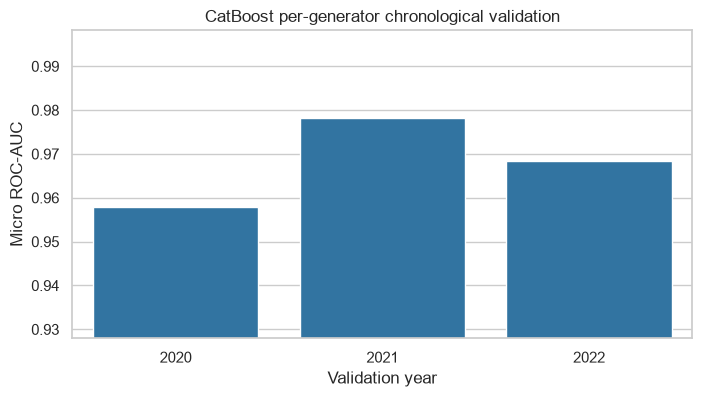

,mean,min
unit,,
Haukeli_G1,0.9098,0.9009
Vinje_G3,0.9492,0.9124
Lio_G1,0.9492,0.9258
Vinje_G2,0.9666,0.9532
Vinje_G1,0.9728,0.9646
Hogga_G1,0.9731,0.9682
Tokke_G4,0.9731,0.9583
Tokke_G2,0.9745,0.9589
Tokke_G1,0.9758,0.9637


In [5]:
# FAST ANALYSIS CELL — no training
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=catboost_fold_scores,
    x="validation_year",
    y="micro_auc",
    color="tab:blue",
    ax=ax,
)
ax.set(
    title="CatBoost per-generator chronological validation",
    xlabel="Validation year",
    ylabel="Micro ROC-AUC",
)
ax.set_ylim(
    max(0.5, catboost_fold_scores["micro_auc"].min() - 0.03),
    min(1.0, catboost_fold_scores["micro_auc"].max() + 0.02),
)
plt.show()

unit_summary = (
    catboost_result["unit_scores"]
    .groupby("unit")["auc"]
    .agg(["mean", "min"])
    .sort_values("mean")
)
display(unit_summary.style.format("{:.4f}"))


## 3. Train on 2015–2022 and create submission

The final tree count for each generator is the median best iteration from the three chronological folds.

In [6]:
# TRAINING CELL B — final CatBoost models and submission
train_rows = rows_for_cases(np.arange(data.n_train_cases))
test_rows = rows_for_cases(
    np.arange(data.n_train_cases, data.n_all_cases)
)
X_train_full = data.X_all.loc[train_rows, FEATURES]
X_test = data.X_all.loc[test_rows, FEATURES]
test_prediction = np.empty(
    (data.n_test_cases, len(data.units), HORIZON),
    dtype=np.float32,
)

for unit_index, unit in enumerate(data.units):
    fold_iterations = catboost_result["best_iterations"][unit]
    final_iterations = max(100, int(np.median(fold_iterations)))
    model = make_catboost(iterations=final_iterations)
    y_train = data.target_cube[:, unit_index, :].reshape(-1)
    model.fit(X_train_full, y_train, verbose=False)
    prediction = model.predict_proba(X_test)[:, 1]
    test_prediction[:, unit_index, :] = prediction.reshape(
        data.n_test_cases, HORIZON
    )
    print(f"{unit:18s}: {final_iterations} trees")

submission_path, submission = make_submission(
    data,
    test_prediction,
    "catboost_per_generator.csv",
)
print("Saved:", submission_path)
display(submission.iloc[:3, :8])


Hogga_G1          : 1068 trees
Tokke_G1          : 727 trees
Tokke_G2          : 514 trees
Tokke_G3          : 467 trees
Tokke_G4          : 503 trees
Lio_G1            : 205 trees
Byrte_G1          : 153 trees
Vinje_G1          : 489 trees
Vinje_G2          : 344 trees
Vinje_G3          : 528 trees
Haukeli_G1        : 100 trees
Songa_G1          : 216 trees
Kjela_G1          : 645 trees
Vesle Kjela_G1    : 425 trees
Saved: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project/submissions/catboost_per_generator.csv


,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6
0,2923,0.147063,0.069569,0.043309,0.030296,0.032459,0.035489,0.014054
1,2924,0.824385,0.847961,0.851314,0.844912,0.831586,0.899074,0.991953
2,2925,0.994110,0.993548,0.994652,0.994427,0.995239,0.997918,0.999143


### Kaggle description

`CatBoost per generator – full engineered features and purged OOF`

Record the public score, but promote this model only if chronological mean/worst-fold performance or blend performance is competitive.
